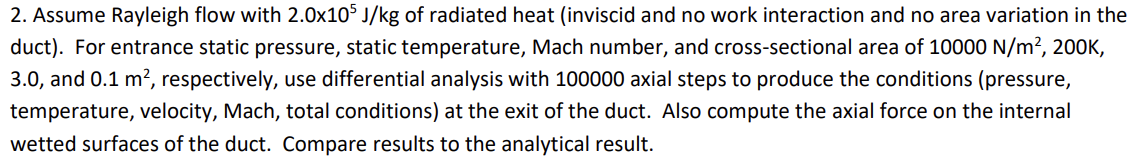

In [9]:
import numpy as np
from quasi_1D import quasi_1D_flow
import matplotlib.pyplot as plt

import scipy as sp

# Numerical

In [16]:
Cp = 1004.5
R = 287
gamma = 1.4

In [17]:
Pi = 10_000
Ti = 200
Mi = 3.0
ui = Mi * np.sqrt(1.4*287*Ti)

L_tube = 1
axial_steps = 100_000

Ai = 0.1

xlist = np.linspace(0,L_tube,axial_steps+1)
Af = lambda x: Ai

q = 2.0e+5

[uout,Tout,Pout], M, x_break, A_break, Thrust = quasi_1D_flow(inlet = [ui,Ti,Pi], Af = Af,N = axial_steps, q = q)

0.0


In [12]:
gamma = 1.4
Tt = Tout*(1+(gamma-1)/2*M**2)
Pt = Pout*(1+(gamma-1)/2*M**2)**(gamma/(gamma-1))


print(f'exit Mach =             {M[-1]}')
print(f'exit Velocity =         {uout[-1]} m/s\n')

print(f'exit Temp =             {Tout[-1]} k')
print(f'exit Total Temp =       {Tt[-1]} k\n')

print(f'exit Pressure =         {Pout[-1]} Pa')
print(f'exit Total Pressure =   {Pt[-1]} Pa\n')

# print(f'exit end area = {A_break}')
print(f'{Thrust =                } N')

exit Mach =             1.5907244230566377
exit Velocity =         715.8572854685287 m/s

exit Temp =             504.02614863993676 k
exit Total Temp =       759.1041243285234 k

exit Pressure =         29938.98319470839 Pa
exit Total Pressure =   125518.00762504048 Pa

Thrust =                -0.003551486948708771 N


# Analytical

In [13]:
f_ray = lambda M: ((1+(gamma-1)/2*M**2)/(1+gamma*M**2)**2)*M**2
M_ray_super = lambda f: np.sqrt(2*f/(1-2*gamma*f-((1-2*(gamma+1)*f)**(1/2)))) 

Tti = Ti*(1+(gamma-1)/2*Mi**2)
Pti = Pi*((1+(gamma-1)/2*Mi**2)**(gamma/(gamma-1)))

f1 = f_ray(Mi)
f2 = (1+q/(Cp*Tti))*f1
Me = M_ray_super(f2)

Tte = f2/f1*Tti
Te = Tte / (1+(gamma-1)/2*Me**2)


Pe = Pi * (1+gamma*Mi**2)/(1+gamma*Me**2)
Pte = Pe*((1+(gamma-1)/2*Me**2)**(gamma/(gamma-1)))

ue = Me * np.sqrt(gamma*R*Te)

rho0 = Pi/(R*Ti)
rho = Pe / (R*Te)


Ae = Ai
Thrust_a = (rho*ue**2+Pe)*Ae - (rho0*ui**2+Pi)*Ai

In [14]:
print(f'exit Mach =             {Me}')
print(f'exit Velocity =         {ue} m/s\n')

print(f'exit Temp =             {Te} k')
print(f'exit Total Temp =       {Tte} k\n')

print(f'exit Pressure =         {Pe} Pa')
print(f'exit Total Pressure =   {Pte} Pa\n')

print(f'{Thrust_a =              } N')

exit Mach =             1.5907221267241787
exit Velocity =         715.8565557179489 m/s

exit Temp =             504.026576224806 k
exit Total Temp =       759.1040318566451 k

exit Pressure =         29939.09394426188 Pa
exit Total Pressure =   125518.04573540877 Pa

Thrust_a =              0.0 N


# Error

In [15]:
print(f'exit Mach error =           {M[-1]-Me}')
print(f'exit Velocity error =       {uout[-1]-ue} m/s\n')

print(f'exit Temp error =           {Tout[-1]-Te} k')
print(f'exit Total Temp error =     {Tt[-1]-Tte} k\n')

print(f'exit Pressure error =       {Pout[-1]-Pe} Pa')
print(f'exit Total Pressure error = {Pt[-1]-Pte} Pa\n')

# print(f'exit end area = {A_break}')
print(f'Thrust Error =              {Thrust - Thrust_a} N')

exit Mach error =           2.296332459073014e-06
exit Velocity error =       0.0007297505798078419 m/s

exit Temp error =           -0.00042758486921457006 k
exit Total Temp error =     9.247187836081139e-05 k

exit Pressure error =       -0.11074955348885851 Pa
exit Total Pressure error = -0.038110368288471363 Pa

Thrust Error =              -0.003551486948708771 N
